# Exploratory Data Analysis (EDA) — Jurnal Utama & 3 Modalitas Modifikasi

- **Jurnal Utama (Repeat — Dataset A):** Selayanti, Putri, & Fahrudin (2024), *Analisis Segmentasi Sentra Wisata Kuliner untuk Optimalisasi Omzet UMKM di Surabaya Menggunakan Metode Agglomerative Hierarchical Clustering*, **JoMMiT** Vol. 8 No. 2, DOI: `10.46961/jommit.v8i2` (`48` SWK Surabaya, Satu Data Surabaya).
- **Dataset Modifikasi (3 Modalitas Valid):**
  1. **Dataset A (Tabular & Teks):** `48` SWK Surabaya + `385` UMKM Surabaya Timur (6 kecamatan) & `1.164` ulasan bahasa asli (`en`/`id`).
  2. **Dataset B (Gambar Indonesia):** Dataset publik serupa (pengganti Mendeley 403 pada **Wiranata & Lestari, 2025, JuTISI, DOI `10.28932/jutisi.v11i1.10284`**): **`fahmindra/padang-cuisine`** (`993` foto masakan Indonesia, `9` kelas seimbang, lisensi ODbL) + `549` foto bersih UMKM/SWK Surabaya Timur (`279.99 MB >= 200 MB`, filter `OpenCLIP` & blur wajah `OpenCV`).
  3. **Dataset C (Dokumen):** `MIDD` (`708` CSV IOB 4 layout — Baviskar et al., 2021, DOI `10.3390/data6070078`) + `CORD-v2` (`200` struk restoran Indonesia — Park et al., 2019, HF `iqbal-rizanta/cord-v2-bucket`) + `3` PDF perizinan penelitian lokal (`pypdf`).

In [1]:
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
try:
    from IPython.display import display
except ImportError:
    display = print

if 'google.colab' in sys.modules:
    from google.colab import drive
    if not Path('/content/drive/MyDrive').exists():
        drive.mount('/content/drive')

def resolve_env(stage='eda'):
    cwd = Path.cwd().resolve()
    for base in [cwd, cwd.parent, cwd.parent.parent, cwd.parent.parent.parent]:
        if (base / 'data' / 'clean').exists() and (base / 'data' / 'gold').exists():
            out = base / 'docs' / 'reports' / stage
            out.mkdir(parents=True, exist_ok=True)
            return {
                'mode': 'local_repo', 'root': base, 'out_dir': out,
                'swk_csv': base / 'data' / 'raw' / 'journal_utama_swk' / 'kode11500kode25245kode3135.csv',
                'clean_tab': base / 'data' / 'clean',
                'photos_dir': base / 'data' / 'clean' / 'photos',
                'feat_store': base / 'data' / 'gold' / 'feature_store.parquet',
                'padang_dir': base / 'data' / 'raw' / 'journal_gambar_padang_id',
                'midd_dir': base / 'data' / 'raw' / 'journal_dokumen_midd' / 'IOB',
                'cord_file': base / 'data' / 'raw' / 'journal_dokumen_cord' / 'cord_v2_receipts_structured.parquet',
                'repeat_res': base / 'docs' / 'reports' / 'journal_repeat',
                'modif_res': base / 'docs' / 'reports' / 'journal_adjust',
                'eval_res': base / 'docs' / 'reports' / 'modeling',
                'bda_res': base / 'docs' / 'reports' / 'bda',
            }
    cands = [cwd, cwd.parent, Path('/content/drive/MyDrive/BDA-2026-Iqbal'), Path(r'G:\My Drive\BDA-2026-Iqbal')]
    if Path('/content/drive/MyDrive').exists():
        cands.extend(Path('/content/drive/MyDrive').glob('**/BDA-2026-Iqbal'))
    for dr in cands:
        if (dr / '04_Dataset_Multimodal_Saya').exists():
            out = dr / '07_Reports_Lengkap_Proyek' / stage
            out.mkdir(parents=True, exist_ok=True)
            return {
                'mode': 'gdrive', 'root': dr, 'out_dir': out,
                'swk_csv': dr / 'Repeat' / 'dataset_jurnal_utama' / 'kode11500kode25245kode3135.csv',
                'clean_tab': dr / '04_Dataset_Multimodal_Saya' / '02_clean' / 'tabular_text',
                'photos_dir': dr / '04_Dataset_Multimodal_Saya' / '02_clean' / 'images',
                'feat_store': dr / '04_Dataset_Multimodal_Saya' / '04_feature_store' / 'feature_store.parquet',
                'padang_dir': dr / 'Modifikasi' / 'dataset_gambar_indonesia_serupa',
                'midd_dir': dr / 'Modifikasi' / 'dataset_dokumen_tambahan' / 'MIDD_Invoice_IOB',
                'cord_file': dr / 'Modifikasi' / 'dataset_dokumen_tambahan' / 'CORD_v2_Receipts_Indonesia' / 'cord_v2_receipts_structured.parquet',
                'repeat_res': dr / 'Repeat' / 'hasil_repeat',
                'modif_res': dr / 'Modifikasi' / 'hasil_modifikasi',
                'eval_res': dr / '07_Reports_Lengkap_Proyek' / 'model_evaluation',
                'bda_res': dr / '07_Reports_Lengkap_Proyek' / 'bda',
            }
    raise FileNotFoundError('Workspace lokal atau Google Drive BDA-2026-Iqbal tidak ditemukan!')

ENV = resolve_env()
if ENV['mode'] == 'local_repo' and str(ENV['root']) not in sys.path:
    sys.path.insert(0, str(ENV['root']))

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 120

def save_and_show(filename: str) -> None:
    out_path = ENV['out_dir'] / filename
    plt.tight_layout()
    plt.savefig(out_path, dpi=180, bbox_inches='tight')
    print(f'Saved: {out_path}')
    plt.show()

print(f"Mode Aktif   : {ENV['mode']}")
print(f"Project Root : {ENV['root']}")
print(f"Output Dir   : {ENV['out_dir']}")

Mode Aktif   : local_repo
Project Root : C:\big-data-analytic
Output Dir   : C:\big-data-analytic\docs\reports\eda


## 1. EDA Dataset Jurnal Utama (48 SWK Surabaya — Gambar 2, 3, & 4 Jurnal)

Dataset Jurnal Utama SWK : 48 baris x 11 kolom


,Kapasitas,Jumlah pelaku usaha,Jumlah pelaku usaha yang omzetnya lebih dari 1 juta rupiah
count,48.00,48.00,48.00
mean,30.08,24.33,17.56
std,18.89,16.06,14.12
min,8.00,7.00,2.00
25%,20.00,15.00,9.00
50%,27.00,20.50,14.00
75%,35.00,30.00,20.25
max,128.00,106.00,82.00


Saved: C:\big-data-analytic\docs\reports\eda\00_eda_jurnal_utama_swk_48.png


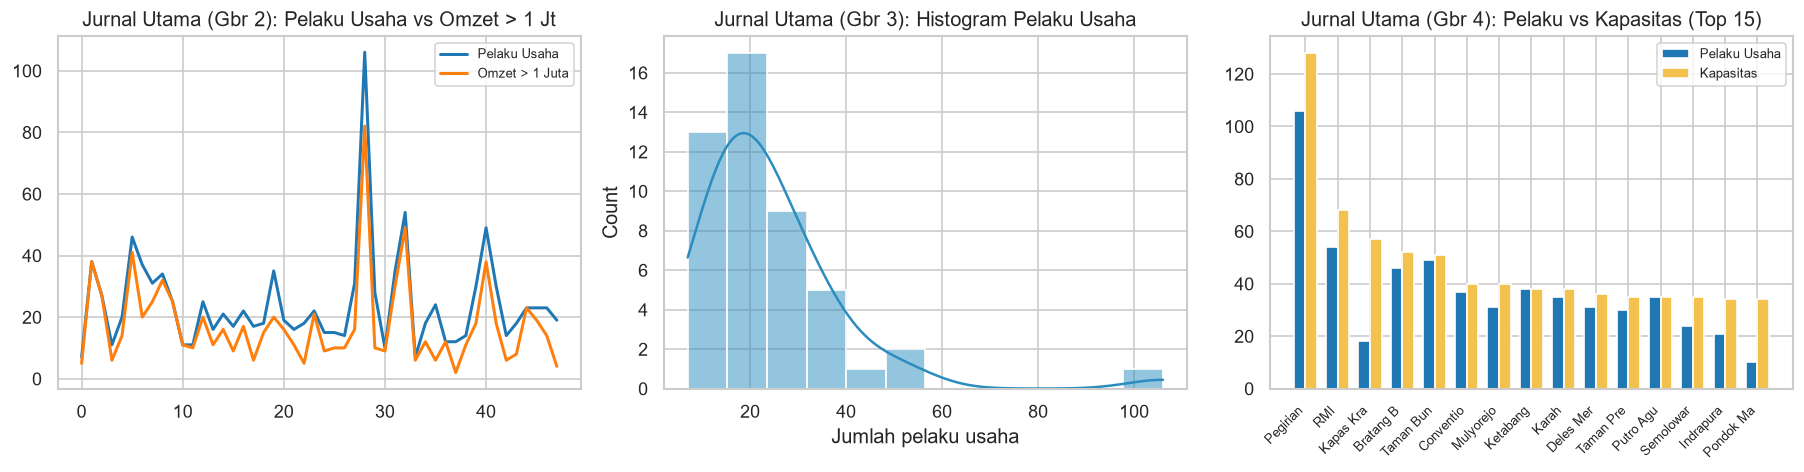

In [2]:
df_swk = pd.read_csv(ENV['swk_csv'], sep=';')
print(f'Dataset Jurnal Utama SWK : {df_swk.shape[0]} baris x {df_swk.shape[1]} kolom')
display(df_swk[['Kapasitas', 'Jumlah pelaku usaha', 'Jumlah pelaku usaha yang omzetnya lebih dari 1 juta rupiah']].describe().round(2))

fig, axes = plt.subplots(1, 3, figsize=(15.2, 4.1))
axes[0].plot(range(len(df_swk)), df_swk['Jumlah pelaku usaha'], label='Pelaku Usaha', color='#1f77b4', lw=1.8)
axes[0].plot(range(len(df_swk)), df_swk['Jumlah pelaku usaha yang omzetnya lebih dari 1 juta rupiah'], label='Omzet > 1 Juta', color='#ff7f0e', lw=1.8)
axes[0].set_title('Jurnal Utama (Gbr 2): Pelaku Usaha vs Omzet > 1 Jt')
axes[0].legend(fontsize=8)

sns.histplot(df_swk['Jumlah pelaku usaha'], bins=12, kde=True, color='#2b8cbe', ax=axes[1])
axes[1].set_title('Jurnal Utama (Gbr 3): Histogram Pelaku Usaha')

top15 = df_swk.sort_values('Kapasitas', ascending=False).head(15)
xp = np.arange(len(top15))
axes[2].bar(xp - 0.18, top15['Jumlah pelaku usaha'], width=0.36, label='Pelaku Usaha', color='#1f77b4')
axes[2].bar(xp + 0.18, top15['Kapasitas'], width=0.36, label='Kapasitas', color='#f2c14e')
axes[2].set_title('Jurnal Utama (Gbr 4): Pelaku vs Kapasitas (Top 15)')
axes[2].set_xticks(xp)
axes[2].set_xticklabels([s.replace('SWK ', '')[:9] for s in top15['Nama sentra']], rotation=45, ha='right', fontsize=7.5)
axes[2].legend(fontsize=8)
save_and_show('00_eda_jurnal_utama_swk_48.png')

## 2. Ringkasan 3 Modalitas Dataset (A: Tabular/Teks, B: Gambar, C: Dokumen)

In [3]:
df_umkm = pd.read_parquet(ENV['clean_tab'] / 'umkm.parquet')
df_ulasan = pd.read_parquet(ENV['clean_tab'] / 'ulasan.parquet')
df_foto = pd.read_parquet(ENV['clean_tab'] / 'foto.parquet')
df_dokumen = pd.read_parquet(ENV['clean_tab'] / 'dokumen.parquet')
df_cord = pd.read_parquet(ENV['cord_file'])
df_padang = pd.read_csv(ENV['padang_dir'] / 'padang_cuisine_metadata.csv')
midd_csvs = list(ENV['midd_dir'].rglob('*.csv'))
photo_mb = round(sum(f.stat().st_size for f in ENV['photos_dir'].rglob('*') if f.is_file() and f.suffix.lower() in ('.jpg', '.jpeg', '.png', '.webp')) / (1024**2), 2)

summary_tbl = pd.DataFrame([
    {'Cabang': 'Dataset A (Repeat)', 'Modalitas': 'Tabular SWK Surabaya (Jurnal Utama)', 'Jumlah': f'{len(df_swk)} SWK (11 var)', 'Sumber': 'Satu Data Surabaya (Selayanti et al., 2024)'},
    {'Cabang': 'Dataset A (Modifikasi)', 'Modalitas': 'Tabular UMKM & Teks Ulasan Asli', 'Jumlah': f'{len(df_umkm)} UMKM, {len(df_ulasan):,} ulasan', 'Sumber': 'Google Places API Surabaya Timur (en/id)'},
    {'Cabang': 'Dataset B1 (Serupa JuTISI)', 'Modalitas': 'Citra Masakan Indonesia (Padang Cuisine)', 'Jumlah': f'{len(df_padang)} foto (9 kelas)', 'Sumber': 'HuggingFace fahmindra/padang-cuisine (ODbL, pengganti Mendeley 403)'},
    {'Cabang': 'Dataset B2 (Lapangan)', 'Modalitas': 'Citra Bersih UMKM & SWK Surabaya Timur', 'Jumlah': f'{len(df_foto)} foto ({photo_mb} MB)', 'Sumber': 'OpenCLIP + OpenCV + YOLOv8 (>= 200 MB)'},
    {'Cabang': 'Dataset C1 (Modifikasi)', 'Modalitas': 'Dokumen Invoice Multi-Layout (MIDD)', 'Jumlah': f'{len(midd_csvs)} CSV IOB (4 layout)', 'Sumber': 'Zenodo 10.5281/zenodo.5113009 (Baviskar et al., 2021)'},
    {'Cabang': 'Dataset C2 (Modifikasi)', 'Modalitas': 'Dokumen Struk Restoran Indonesia', 'Jumlah': f'{len(df_cord)} struk + 10 sampel PNG', 'Sumber': 'CORD-v2 (Park et al., 2019; HF cord-v2-bucket)'},
    {'Cabang': 'Dataset C3 (Modifikasi)', 'Modalitas': 'Dokumen Perizinan Lokal (PDF)', 'Jumlah': f'{len(df_dokumen)} PDF ({int(df_dokumen["pages"].sum())} hal.)', 'Sumber': 'Ekstraksi pypdf surat izin penelitian SWK'},
])
display(summary_tbl)

,Cabang,Modalitas,Jumlah,Sumber
0,Dataset A (Repeat),Tabular SWK Surabaya (Jurnal Utama),48 SWK (11 var),"Satu Data Surabaya (Selayanti et al., 2024)"
1,Dataset A (Modifikasi),Tabular UMKM & Teks Ulasan Asli,"385 UMKM, 1,164 ulasan",Google Places API Surabaya Timur (en/id)
2,Dataset B1 (Serupa JuTISI),Citra Masakan Indonesia (Padang Cuisine),993 foto (9 kelas),"HuggingFace fahmindra/padang-cuisine (ODbL, pe..."
3,Dataset B2 (Lapangan),Citra Bersih UMKM & SWK Surabaya Timur,549 foto (279.99 MB),OpenCLIP + OpenCV + YOLOv8 (>= 200 MB)
4,Dataset C1 (Modifikasi),Dokumen Invoice Multi-Layout (MIDD),708 CSV IOB (4 layout),Zenodo 10.5281/zenodo.5113009 (Baviskar et al....
5,Dataset C2 (Modifikasi),Dokumen Struk Restoran Indonesia,200 struk + 10 sampel PNG,"CORD-v2 (Park et al., 2019; HF cord-v2-bucket)"
6,Dataset C3 (Modifikasi),Dokumen Perizinan Lokal (PDF),3 PDF (7 hal.),Ekstraksi pypdf surat izin penelitian SWK


## 3. EDA Dataset A — Sebaran Kecamatan, Rating, & Sinyal Teks Ulasan UMKM

Saved: C:\big-data-analytic\docs\reports\eda\01_distribusi_umkm_dan_rating.png


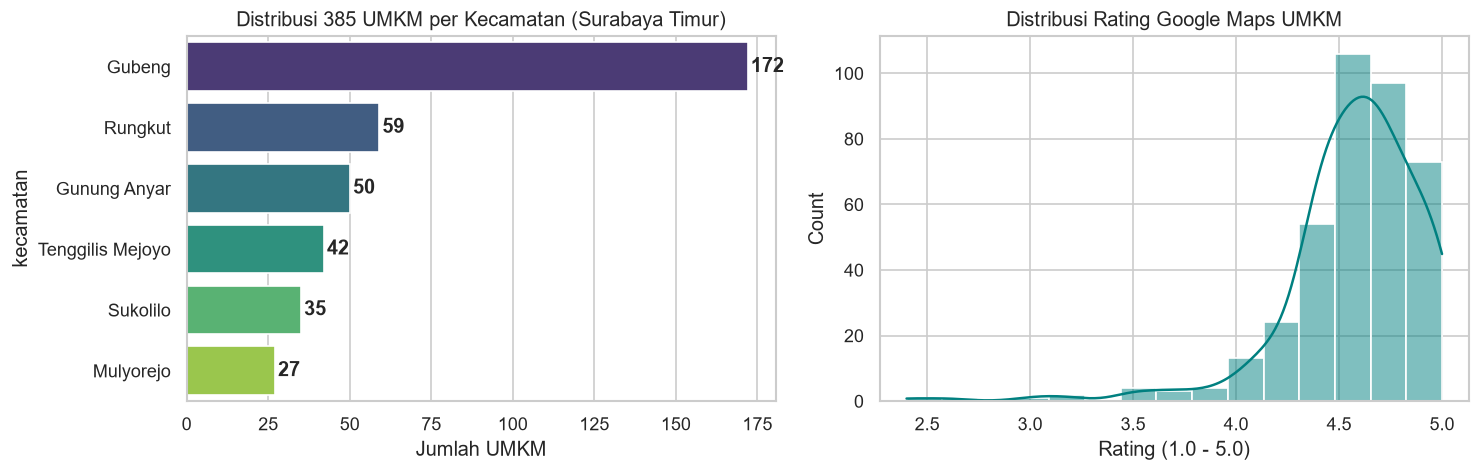

,Bahasa,Jumlah Ulasan,Persentase (%)
0,en,1040,89.35
1,id,124,10.65


Saved: C:\big-data-analytic\docs\reports\eda\02_frekuensi_indikator_ulasan.png


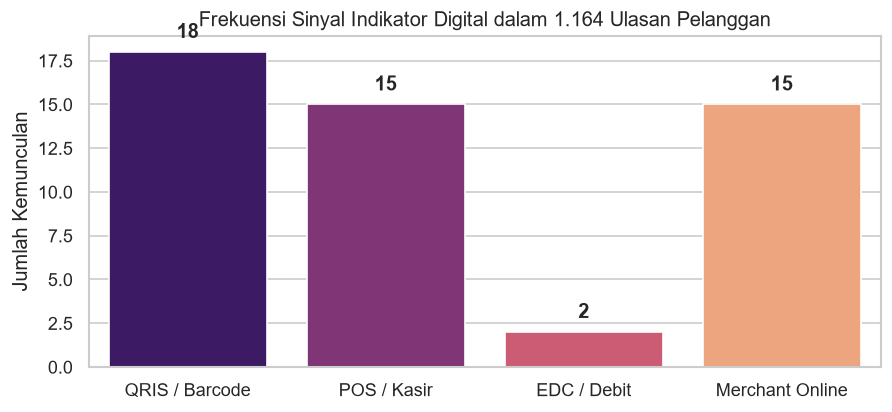

In [4]:
kec_counts = df_umkm['kecamatan'].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.1))
sns.barplot(x=kec_counts.values, y=kec_counts.index, hue=kec_counts.index, palette='viridis', legend=False, ax=axes[0])
axes[0].set_title('Distribusi 385 UMKM per Kecamatan (Surabaya Timur)')
axes[0].set_xlabel('Jumlah UMKM')
for i, v in enumerate(kec_counts.values):
    axes[0].text(v + 1.0, i, str(v), va='center', fontweight='bold')

sns.histplot(df_umkm['rating'].dropna(), bins=15, kde=True, color='teal', ax=axes[1])
axes[1].set_title('Distribusi Rating Google Maps UMKM')
axes[1].set_xlabel('Rating (1.0 - 5.0)')
save_and_show('01_distribusi_umkm_dan_rating.png')

lang_counts = df_ulasan['bahasa'].value_counts().rename_axis('Bahasa').reset_index(name='Jumlah Ulasan')
lang_counts['Persentase (%)'] = (lang_counts['Jumlah Ulasan'] / len(df_ulasan) * 100).round(2)
display(lang_counts)

sinyal_cols = ['mention_qris', 'mention_pos', 'mention_edc', 'mention_online']
sinyal_sum = df_ulasan[sinyal_cols].sum()
labels = ['QRIS / Barcode', 'POS / Kasir', 'EDC / Debit', 'Merchant Online']
plt.figure(figsize=(7.6, 3.6))
sns.barplot(x=labels, y=sinyal_sum.values, hue=labels, palette='magma', legend=False)
plt.title('Frekuensi Sinyal Indikator Digital dalam 1.164 Ulasan Pelanggan')
plt.ylabel('Jumlah Kemunculan')
for i, v in enumerate(sinyal_sum.values):
    plt.text(i, v + 0.8, str(int(v)), ha='center', fontweight='bold')
save_and_show('02_frekuensi_indikator_ulasan.png')

## 4. EDA Dataset B — Citra Bersih UMKM (`549` Foto) & Citra Masakan Indonesia Serupa (`993` Foto)

Saved: C:\big-data-analytic\docs\reports\eda\03_distribusi_indikator_citra_yolo.png


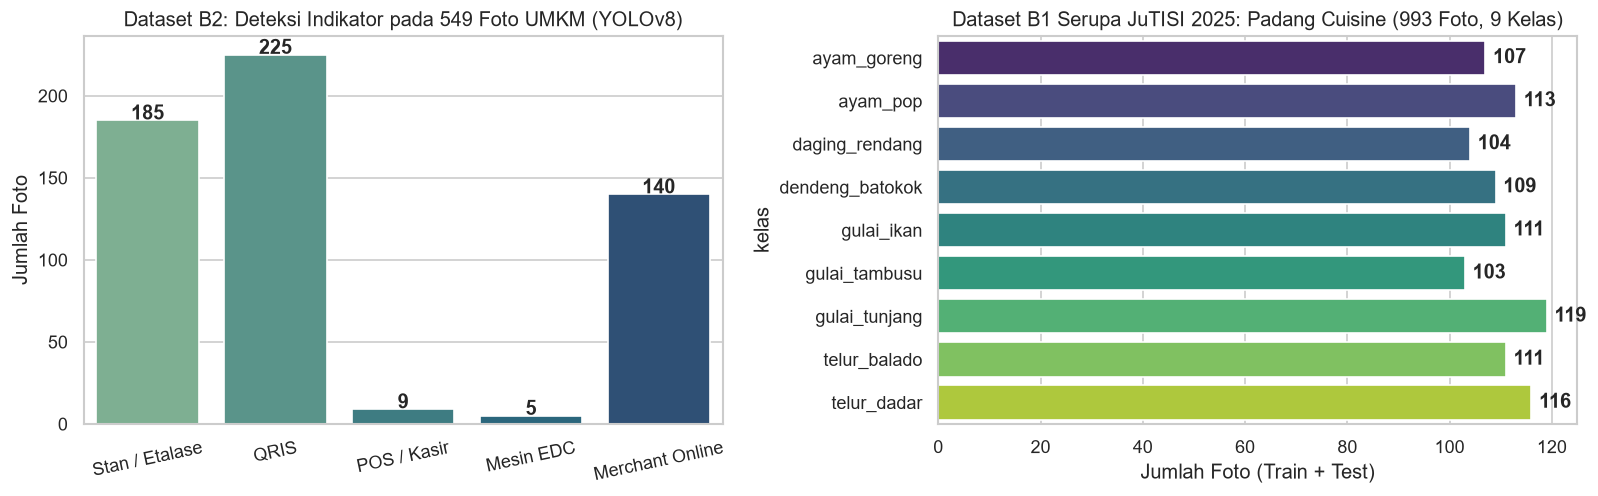

Sumber Citra Bersih UMKM/SWK    : {'google_places_api': 505, 'survei_lapangan_swk': 44}
Total Wajah Diburamkan (OpenCV) : 824 wajah
Resolusi Rata-Rata Padang Food  : 730 x 518 px ({'train': 813, 'test': 180})


In [5]:
ind_cols = ['has_stan', 'has_qris', 'has_pos', 'has_edc', 'has_merchant_online']
ind_labels = ['Stan / Etalase', 'QRIS', 'POS / Kasir', 'Mesin EDC', 'Merchant Online']
ind_counts = [int(df_foto[c].sum()) if c in df_foto.columns else 0 for c in ind_cols]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.3))
sns.barplot(x=ind_labels, y=ind_counts, hue=ind_labels, palette='crest', legend=False, ax=axes[0])
axes[0].set_title('Dataset B2: Deteksi Indikator pada 549 Foto UMKM (YOLOv8)')
axes[0].set_ylabel('Jumlah Foto'); axes[0].tick_params(axis='x', rotation=12)
for i, v in enumerate(ind_counts):
    axes[0].text(i, v + 0.5, str(v), ha='center', fontweight='bold')

pad_cnt = df_padang['kelas'].value_counts().sort_index()
sns.barplot(x=pad_cnt.values, y=pad_cnt.index, hue=pad_cnt.index, palette='viridis', legend=False, ax=axes[1])
axes[1].set_title(f'Dataset B1 Serupa JuTISI 2025: Padang Cuisine ({len(df_padang)} Foto, 9 Kelas)')
axes[1].set_xlabel('Jumlah Foto (Train + Test)')
for i, v in enumerate(pad_cnt.values):
    axes[1].text(v + 1.5, i, str(v), va='center', fontweight='bold')
save_and_show('03_distribusi_indikator_citra_yolo.png')

print('Sumber Citra Bersih UMKM/SWK    :', df_foto['sumber'].value_counts().to_dict())
print(f'Total Wajah Diburamkan (OpenCV) : {int(df_foto["face_blurred_count"].sum())} wajah')
print(f'Resolusi Rata-Rata Padang Food  : {df_padang["width"].mean():.0f} x {df_padang["height"].mean():.0f} px ({df_padang["split"].value_counts().to_dict()})')

## 5. EDA Dataset C — Dokumen Invoice MIDD (`708` CSV IOB), Struk Indonesia CORD-v2 (`200`), & 3 PDF

Saved: C:\big-data-analytic\docs\reports\eda\04_eda_dokumen_midd_dan_cord.png


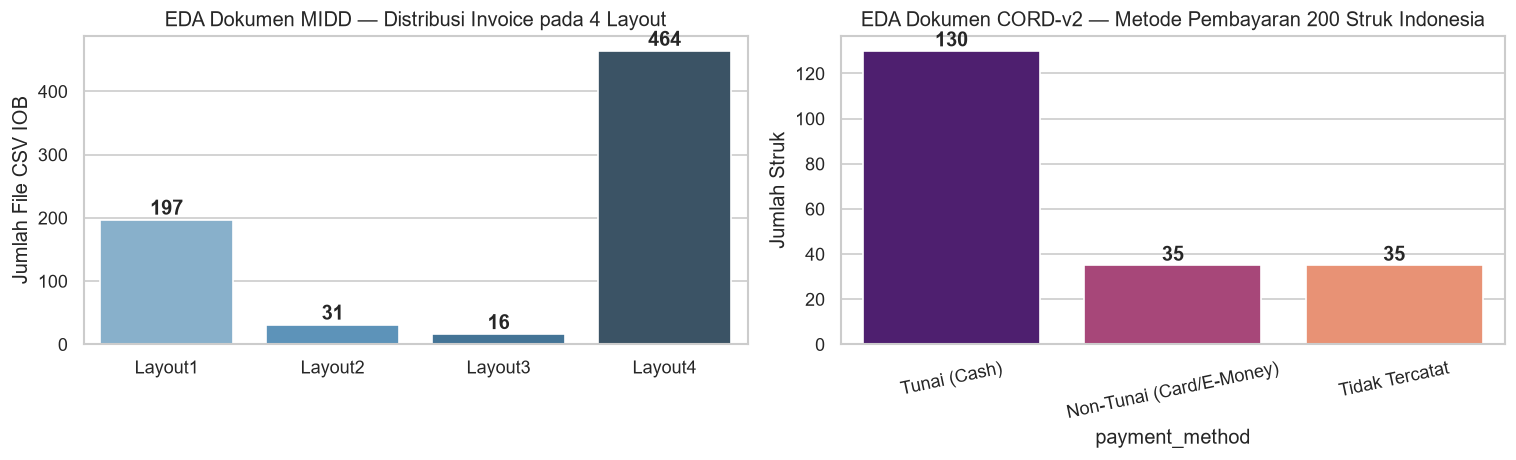

Statistik Nominal Transaksi Struk CORD-v2 -> Median: Rp 48,000 | Mean: Rp 213,116


,dok_id,file_name,pages,file_size_kb,institusi
0,DOK_01,Proposal_Izin_Penelitian.pdf,3,126.11,Dinas Koperasi UKM dan Perdagangan Kota Suraba...
1,DOK_02,Surat_Dinas_Koperasi.pdf,2,181.57,Dinas Koperasi UKM dan Perdagangan Kota Suraba...
2,DOK_03,surat_izin_penelitian.pdf,2,138.90,Dinas Koperasi UKM dan Perdagangan Kota Suraba...


In [6]:
layout_counts = {d.name: len(list(d.glob('*.csv'))) for d in sorted(ENV['midd_dir'].iterdir()) if d.is_dir()}
valid_idr = df_cord['total_price_idr'].dropna()
valid_idr = valid_idr[(valid_idr >= 1000) & (valid_idr <= 10_000_000)]

fig, axes = plt.subplots(1, 2, figsize=(12.8, 4.0))
sns.barplot(x=list(layout_counts.keys()), y=list(layout_counts.values()), hue=list(layout_counts.keys()), palette='Blues_d', legend=False, ax=axes[0])
axes[0].set_title('EDA Dokumen MIDD — Distribusi Invoice pada 4 Layout')
axes[0].set_ylabel('Jumlah File CSV IOB')
for i, v in enumerate(layout_counts.values()):
    axes[0].text(i, v + 8, str(v), ha='center', fontweight='bold')

pay_cnt = df_cord['payment_method'].value_counts()
sns.barplot(x=pay_cnt.index, y=pay_cnt.values, hue=pay_cnt.index, palette='magma', legend=False, ax=axes[1])
axes[1].set_title('EDA Dokumen CORD-v2 — Metode Pembayaran 200 Struk Indonesia')
axes[1].set_ylabel('Jumlah Struk'); axes[1].tick_params(axis='x', rotation=12)
for i, v in enumerate(pay_cnt.values):
    axes[1].text(i, v + 2, str(v), ha='center', fontweight='bold')
save_and_show('04_eda_dokumen_midd_dan_cord.png')

print(f'Statistik Nominal Transaksi Struk CORD-v2 -> Median: Rp {int(valid_idr.median()):,} | Mean: Rp {int(valid_idr.mean()):,}')
display(df_dokumen[['dok_id', 'file_name', 'pages', 'file_size_kb', 'institusi']])